# SECOM: failure detection under an inspection budget

I compared 50 fixed base configurations and a predeclared rank blend to ask how many failures can be flagged when only 20% of a completed batch can be reviewed. The candidate set includes forests, boosting, support-vector methods, linear/discriminant models, nearest neighbors, and pass-only novelty detectors.

This notebook audits the completed run; it does not search another model or choose a cutoff on assessment labels. The latest time block was excluded from fitting and selection within this run. SECOM was explored previously, so this is not historically unseen or external evidence.

In [1]:
import json
from hashlib import sha256
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from sklearn.metrics import average_precision_score
from smartfab.policies import capacity_mask, evaluate_policy, threshold_mask

ROOT = Path.cwd()
OUT = ROOT / 'manufacturing_results'
metrics = json.loads((OUT / 'metrics.json').read_text())
protocol = json.loads((OUT / 'protocol.json').read_text())
selection = json.loads((OUT / 'selection.json').read_text())
assert sha256((OUT / 'protocol.json').read_bytes()).hexdigest() == metrics['protocol_sha256']
assert sha256((OUT / 'selection.json').read_bytes()).hexdigest() == metrics['selection_sha256']
for name, expected in protocol['source_sha256'].items():
    assert sha256((ROOT / name).read_bytes()).hexdigest() == expected, name
print(f"Frozen winner: {selection['winner']}; {len(protocol['catalog'])} base configurations plus one rank blend.")


Frozen winner: knn_k100_neighbors5; 50 base configurations plus one rank blend.


## 1. Fix the production question before choosing the model

The primary metric is failure recall at an exact per-block 20% review budget. All candidates share the same three expanding development windows; AP breaks ties. Native missing-value handling and missingness indicators are alternatives to imputation, and supervised feature selection is fitted only on training rows. Novelty detectors fit their preprocessing and model on passing training observations only.

The model-selection question concerns limited inspection resources. It does not assume that an alert prevents a defect or changes factory throughput.

,rows,failures,first,last
partition,,,,
development,1253,87,2008-07-19 11:55:00,2008-10-02 19:25:00
temporal_assessment,314,17,2008-10-02 20:54:00,2008-10-17 06:07:00


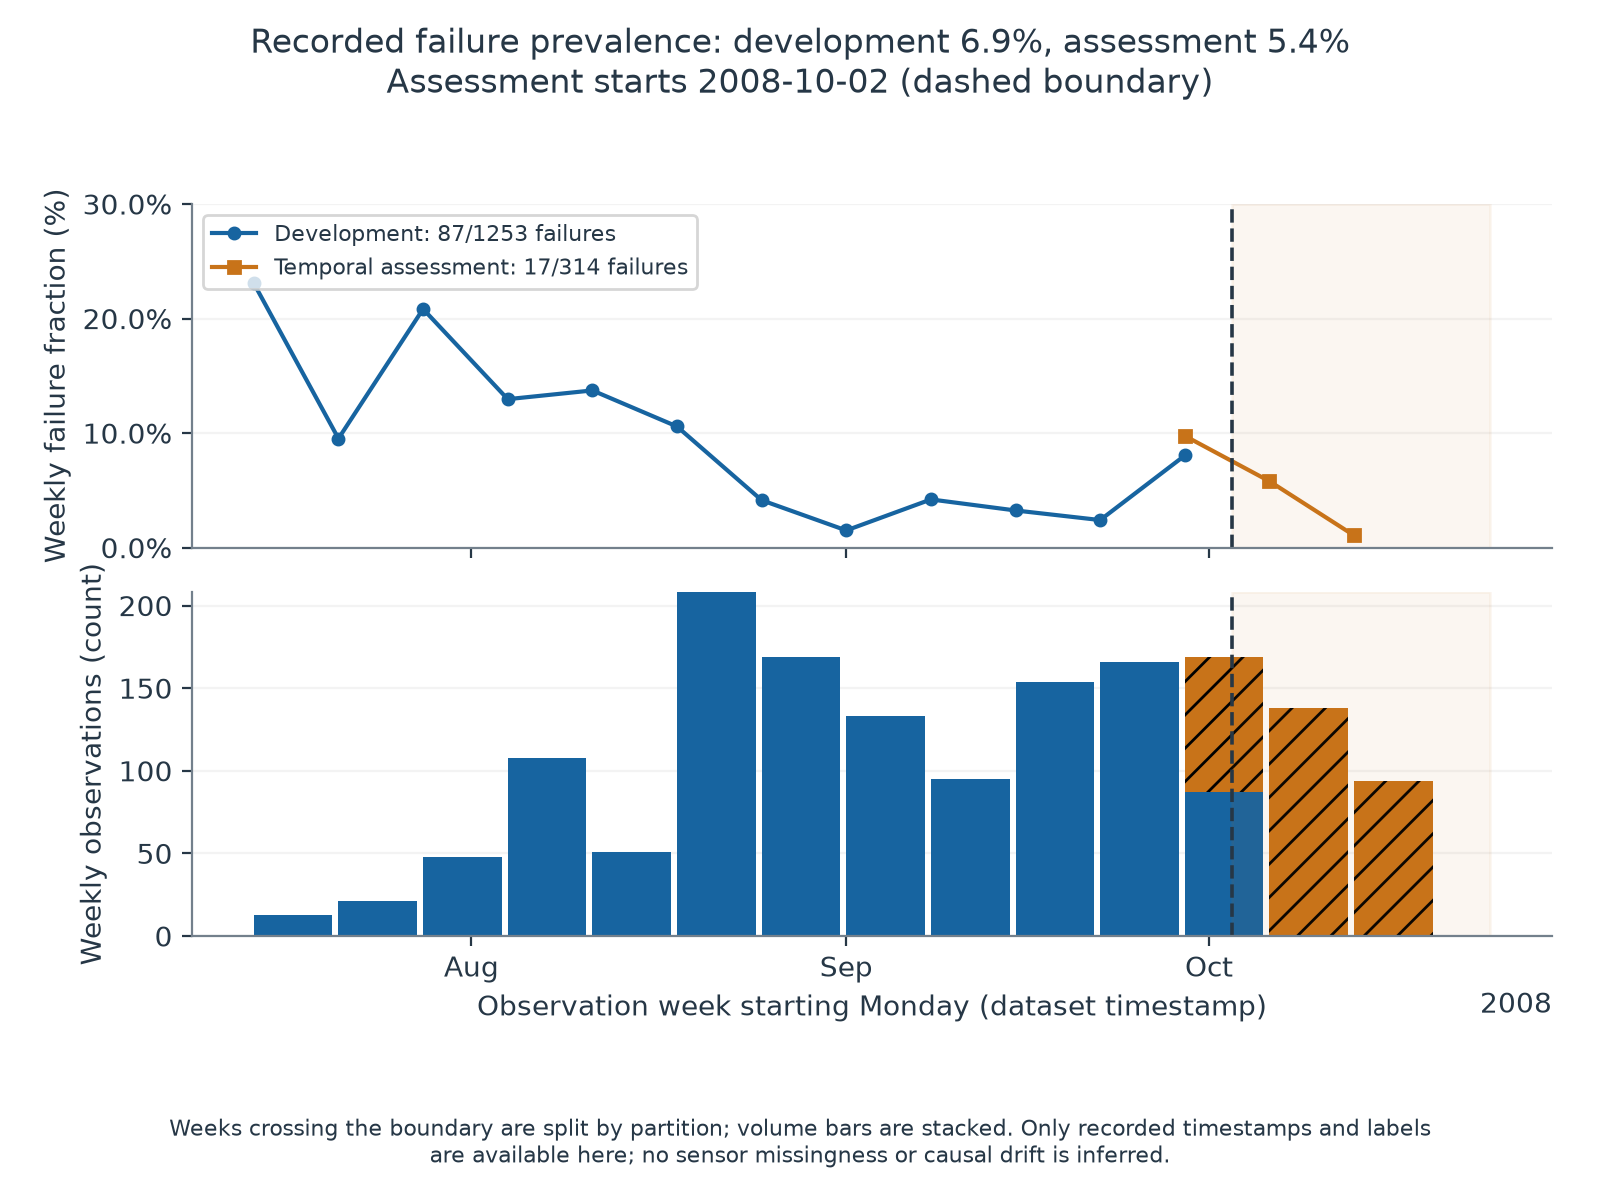

In [2]:
manifest = pd.read_csv(OUT / 'split_manifest.csv', parse_dates=['timestamp'])
dev = manifest.loc[manifest.partition.eq('development')]
assessment = manifest.loc[manifest.partition.eq('temporal_assessment')]
assert set(dev.row_id).isdisjoint(assessment.row_id)
assert dev.timestamp.max() < assessment.timestamp.min()
display(manifest.groupby('partition').agg(rows=('row_id','size'), failures=('label','sum'), first=('timestamp','min'), last=('timestamp','max')))
display(Image(filename=str(OUT / 'figures/temporal_evaluation.png'), width=900))


## 2. Reconstruct the development selection

I selected by recorded forward-validation failures caught at the fixed review capacity, then mean block AP, then fixed catalog order. The blend members were determined on development data, and the blend has no fitted weights. Search statistics are optimistic after selecting among many configurations; they are not an independent performance estimate.

,selection_rank,candidate,true_positives,failure_support,recall,mean_block_ap
0,1,knn_k100_neighbors5,12,28,0.428571,0.082934
1,2,rank_blend_top2,11,28,0.392857,0.209271
2,3,rf_leaf2_none,11,28,0.392857,0.191999
3,4,xgb_k100_depth2_weighttrain_ratio,11,28,0.392857,0.147633
4,5,xgb_kall_depth2_weight1,11,28,0.392857,0.141397
5,6,rf_leaf8_none,11,28,0.392857,0.138460
6,7,xgb_k100_depth3_weight1,11,28,0.392857,0.133503
7,8,v2_rf_knn_smote,11,28,0.392857,0.126895
8,9,xgb_kall_depth2_weighttrain_ratio,10,28,0.357143,0.161361
9,10,rf_leaf2_balanced,10,28,0.357143,0.120953


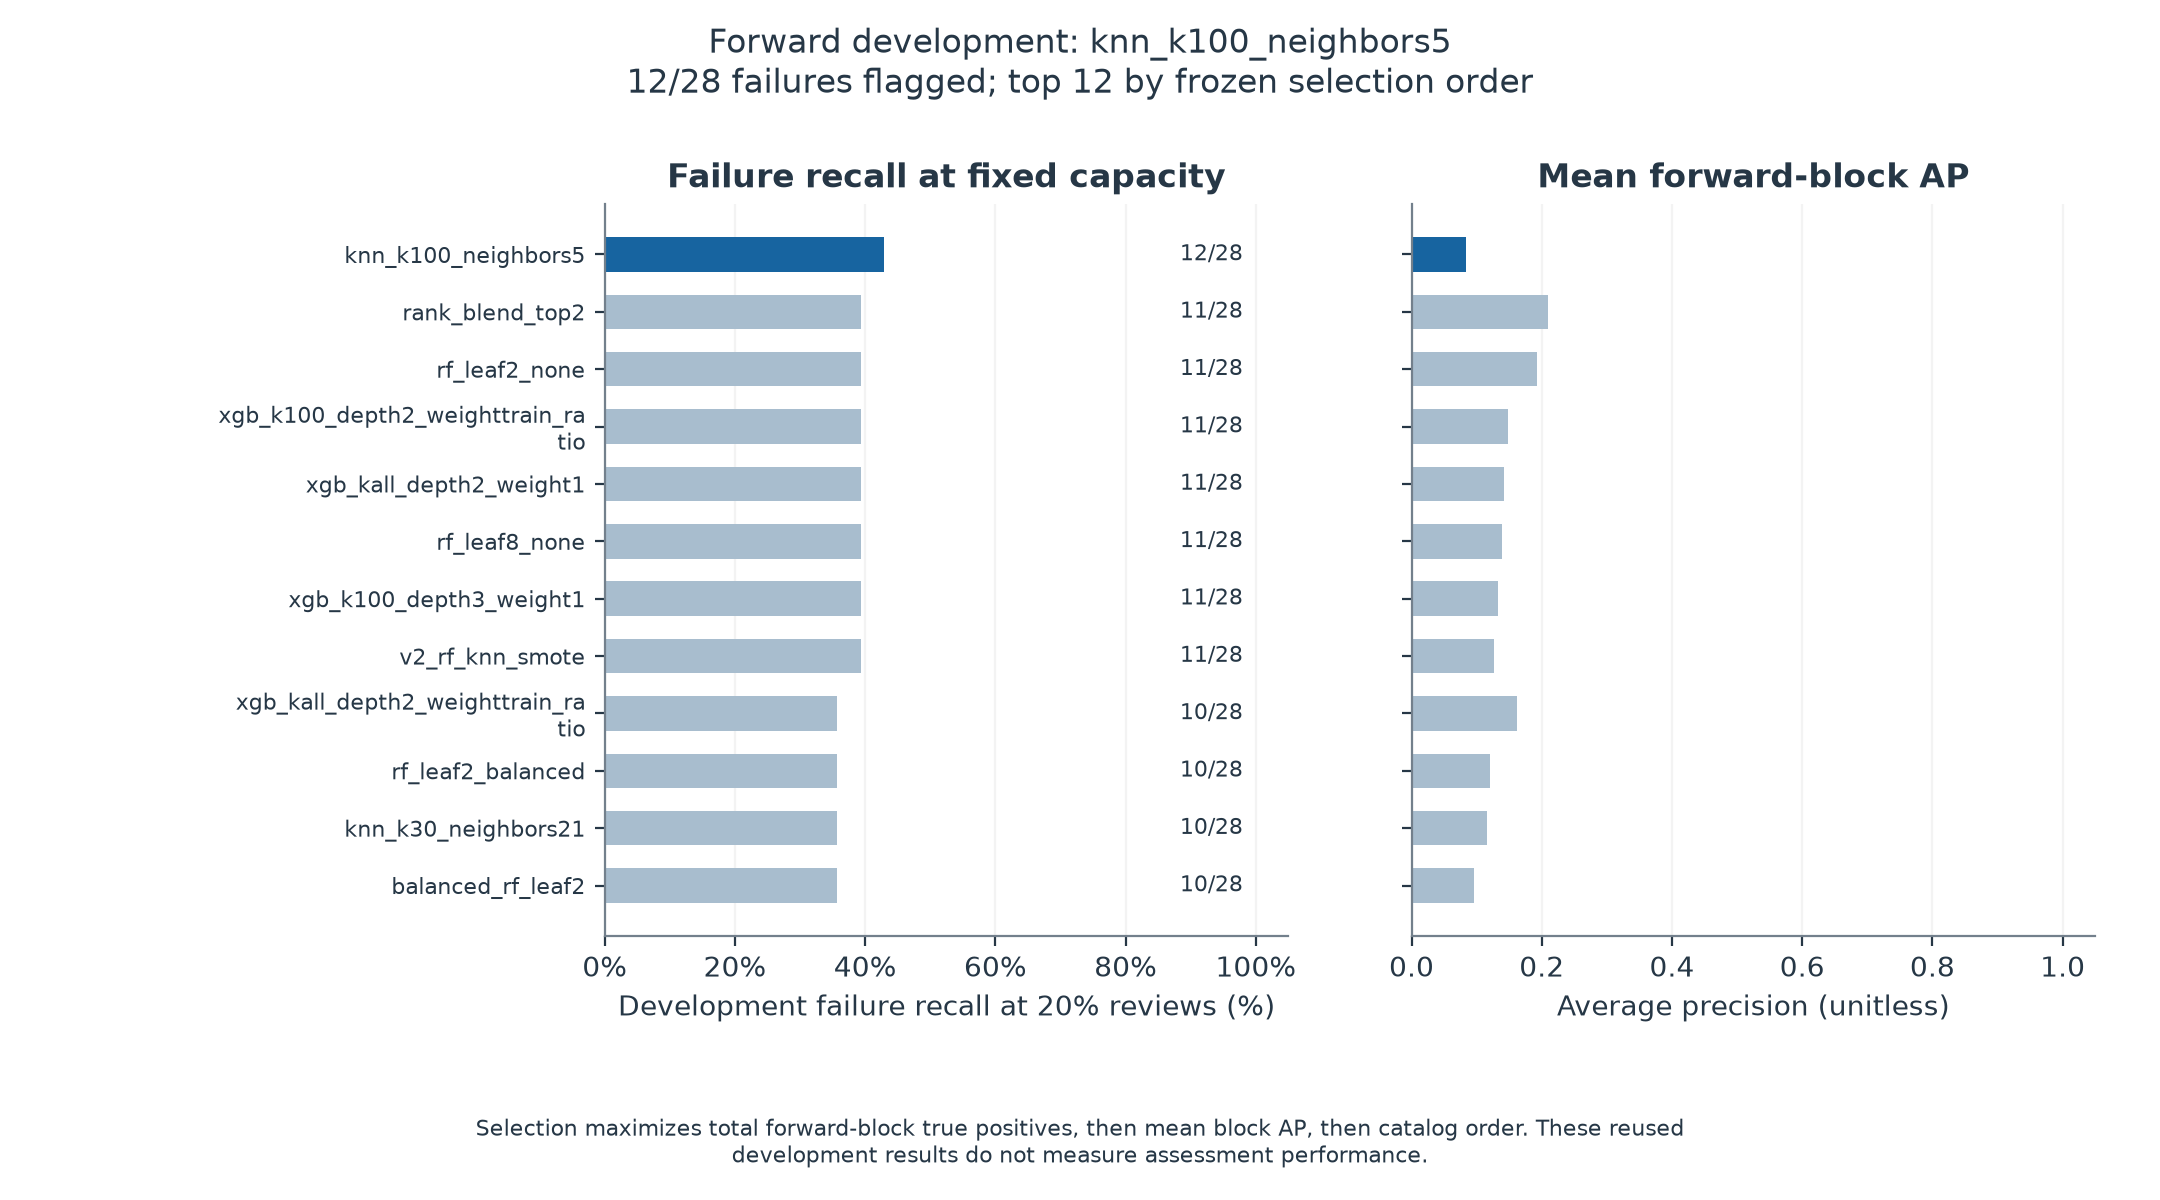

In [3]:
search = pd.read_csv(OUT / 'search_summary.csv')
forward = pd.read_csv(OUT / 'forward_predictions.csv', float_precision='round_trip')
assert len(search) == len(protocol['catalog']) + 1
assert search.iloc[0].candidate == selection['winner']
assert set(forward.row_id) <= set(dev.row_id)
assert not forward.duplicated(['candidate','row_id']).any()
for name, rows in forward.groupby('candidate'):
    caught, aps = 0, []
    for _, block in rows.groupby('block'):
        mask = capacity_mask(block.score, block.row_id, protocol['config']['review_fraction'], protocol['config']['seed'])
        caught += evaluate_policy(block.label, mask)['true_positives']
        aps.append(average_precision_score(block.label, block.score))
    saved = search.loc[search.candidate.eq(name)].iloc[0]
    assert caught == saved.true_positives
    np.testing.assert_allclose(np.mean(aps), saved.mean_block_ap)
display(search[['selection_rank','candidate','true_positives','failure_support','recall','mean_block_ap']].head(12))
display(Image(filename=str(OUT / 'figures/model_search.png'), width=1000))


## 3. Assess the frozen decision on later observations

The selected recipe and the historical v2 recipe are both refitted on the same earlier development observations. Each ranking receives the same number of reviews on the same latest block. The theoretical random expectation and its hypergeometric catch range describe chance allocations at that capacity; they are not an improvement confidence interval.

,strategy,alarm_count,true_positives,false_positives,false_negatives,precision,recall
0,selected,62,5,57,12,0.080645,0.294118
1,v2_reference,62,5,57,12,0.080645,0.294118
2,dummy_reference,62,4,58,13,0.064516,0.235294


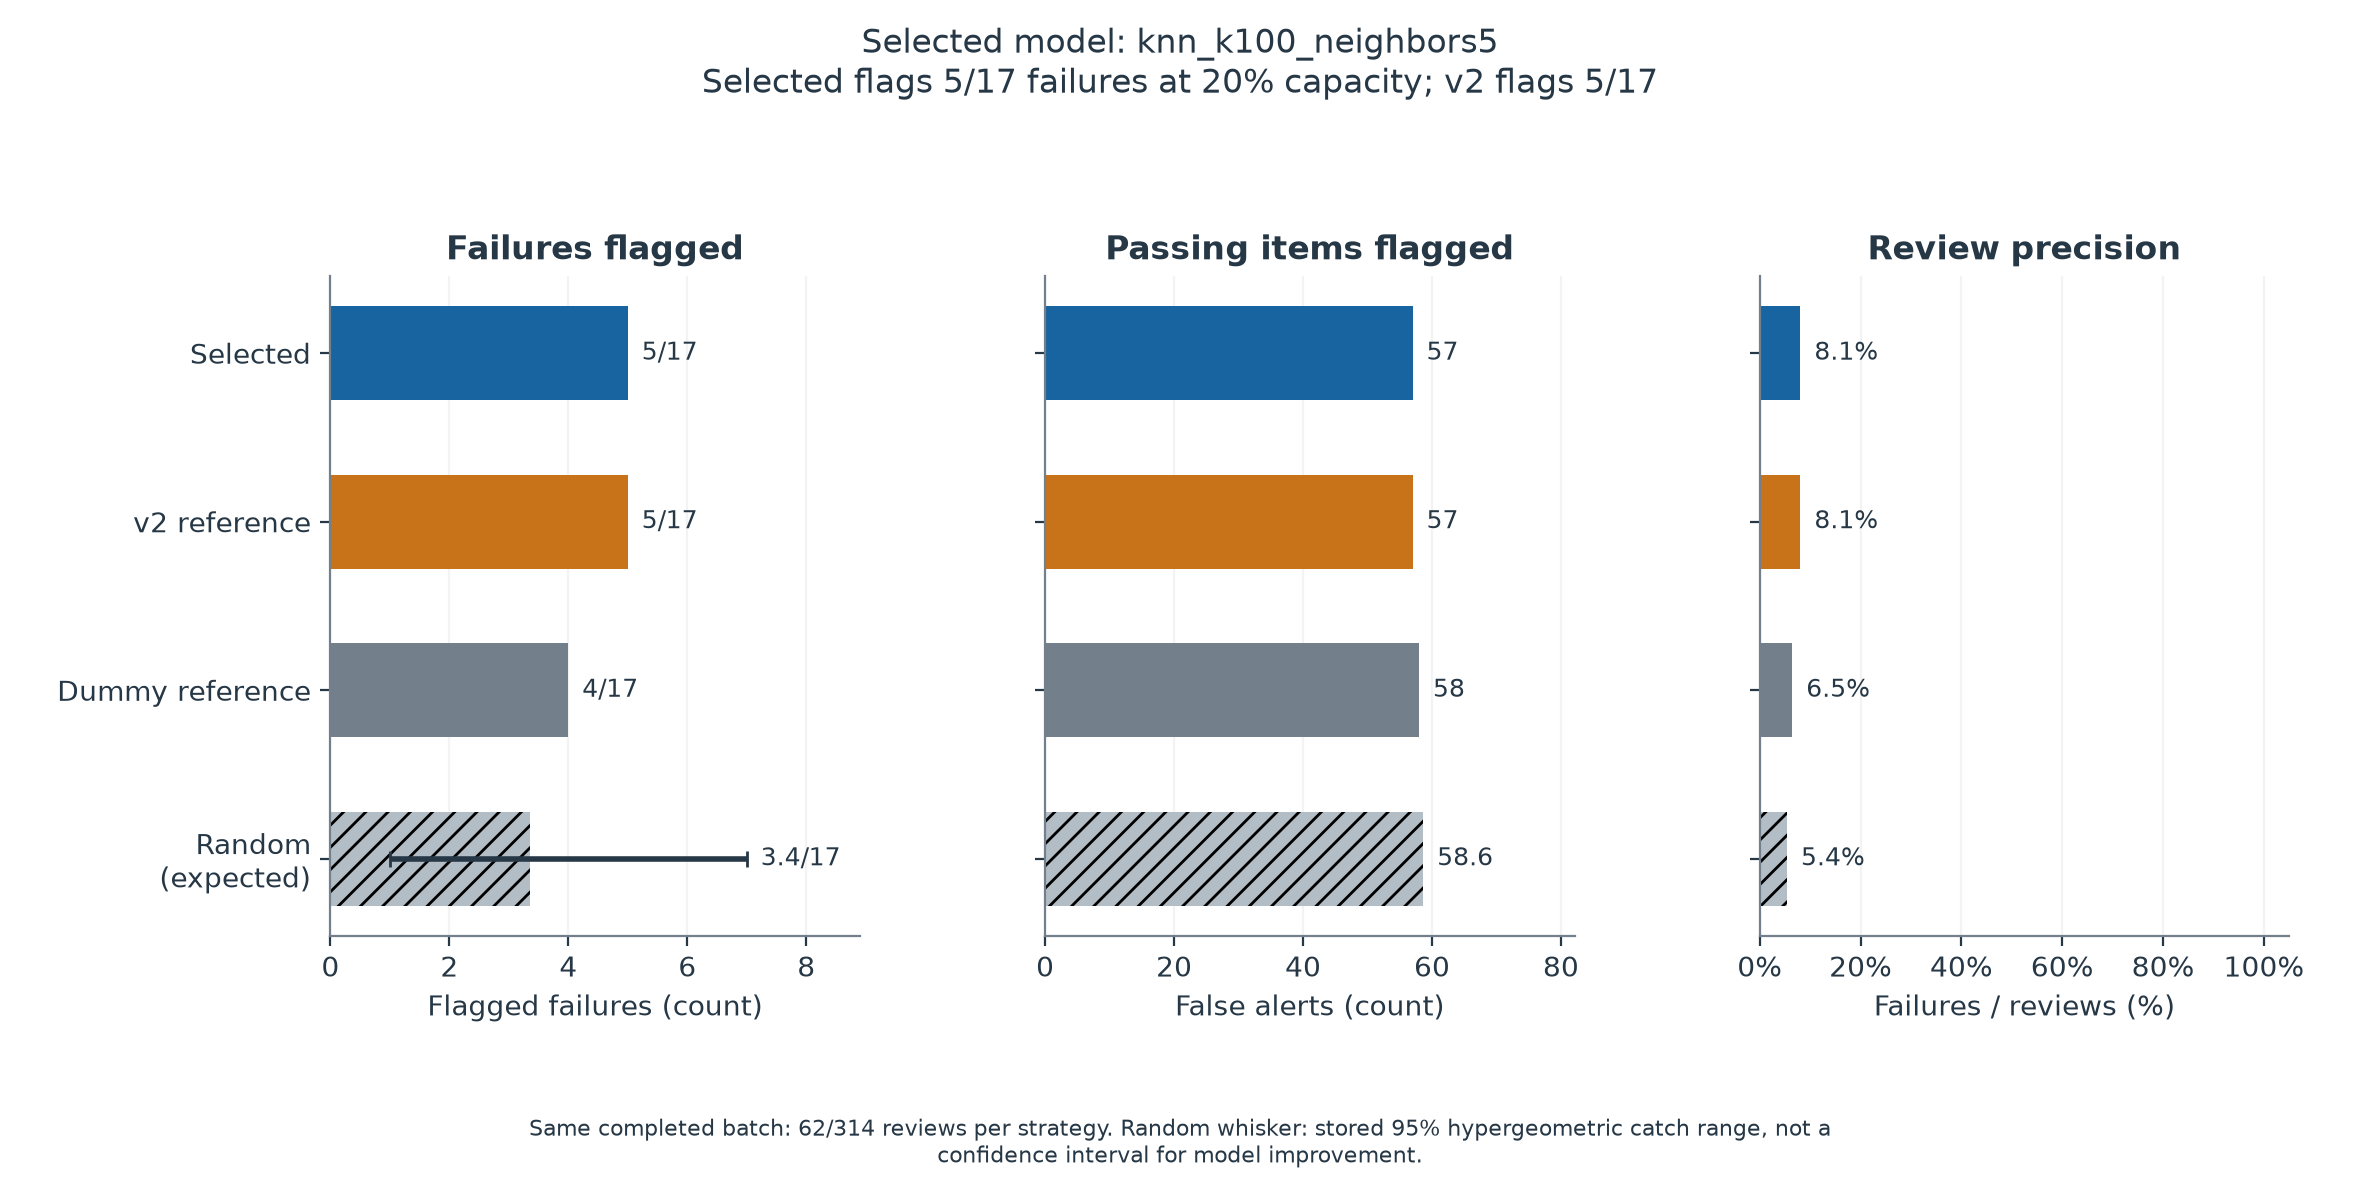

In [4]:
predictions = pd.read_csv(OUT / 'assessment_predictions.csv', float_precision='round_trip')
reconstructed = []
for name, rows in predictions.groupby('strategy',sort=False):
    assert set(rows.row_id) == set(assessment.row_id)
    mask = capacity_mask(rows.score, rows.row_id, protocol['config']['review_fraction'], protocol['config']['seed'])
    np.testing.assert_array_equal(mask, rows.review.astype(bool))
    result = evaluate_policy(rows.label, mask)
    saved = metrics['assessment'][name]['capacity']
    for key in ('true_positives','false_positives','false_negatives','true_negatives','alarm_count'):
        assert result[key] == saved[key]
    np.testing.assert_allclose(average_precision_score(rows.label,rows.score), metrics['assessment'][name]['average_precision'])
    reconstructed.append({'strategy':name,**result})
display(pd.DataFrame(reconstructed)[['strategy','alarm_count','true_positives','false_positives','false_negatives','precision','recall']])
display(Image(filename=str(OUT / 'figures/outcome_summary.png'), width=1100))


In [5]:
selected = metrics['assessment']['selected']['capacity']
reference = metrics['assessment']['v2_reference']['capacity']
delta = selected['true_positives'] - reference['true_positives']
display(Markdown(f"**Takeaway:** the selected method catches **{selected['true_positives']}/{selected['failure_support']}** failures with **{selected['alarm_count']}** reviews and **{selected['false_positives']}** false alerts. The same-budget difference versus v2 is **{delta:+d} failures**. This run does not establish a detection improvement when the difference is zero, and does not establish production benefits."))


**Takeaway:** the selected method catches **5/17** failures with **62** reviews and **57** false alerts. The same-budget difference versus v2 is **+0 failures**. This run does not establish a detection improvement when the difference is zero, and does not establish production benefits.

## 4. Show the detection/workload frontier

The reported 5%, 10%, 20%, 30% and 50% budgets are descriptive policies on the already frozen rankings. The winner remains determined at 20%; a higher-recall budget is not relabeled as a better result without disclosing its additional reviews. The secondary F2 score threshold is selected from development OOF scores and cannot guarantee a future alert-rate cap.

,review_fraction,alarm_count,true_positives,false_positives,false_negatives,precision,recall
0,0.05,15,2,13,15,0.133333,0.117647
1,0.10,31,3,28,14,0.096774,0.176471
2,0.20,62,5,57,12,0.080645,0.294118
3,0.30,94,8,86,9,0.085106,0.470588
4,0.50,157,10,147,7,0.063694,0.588235


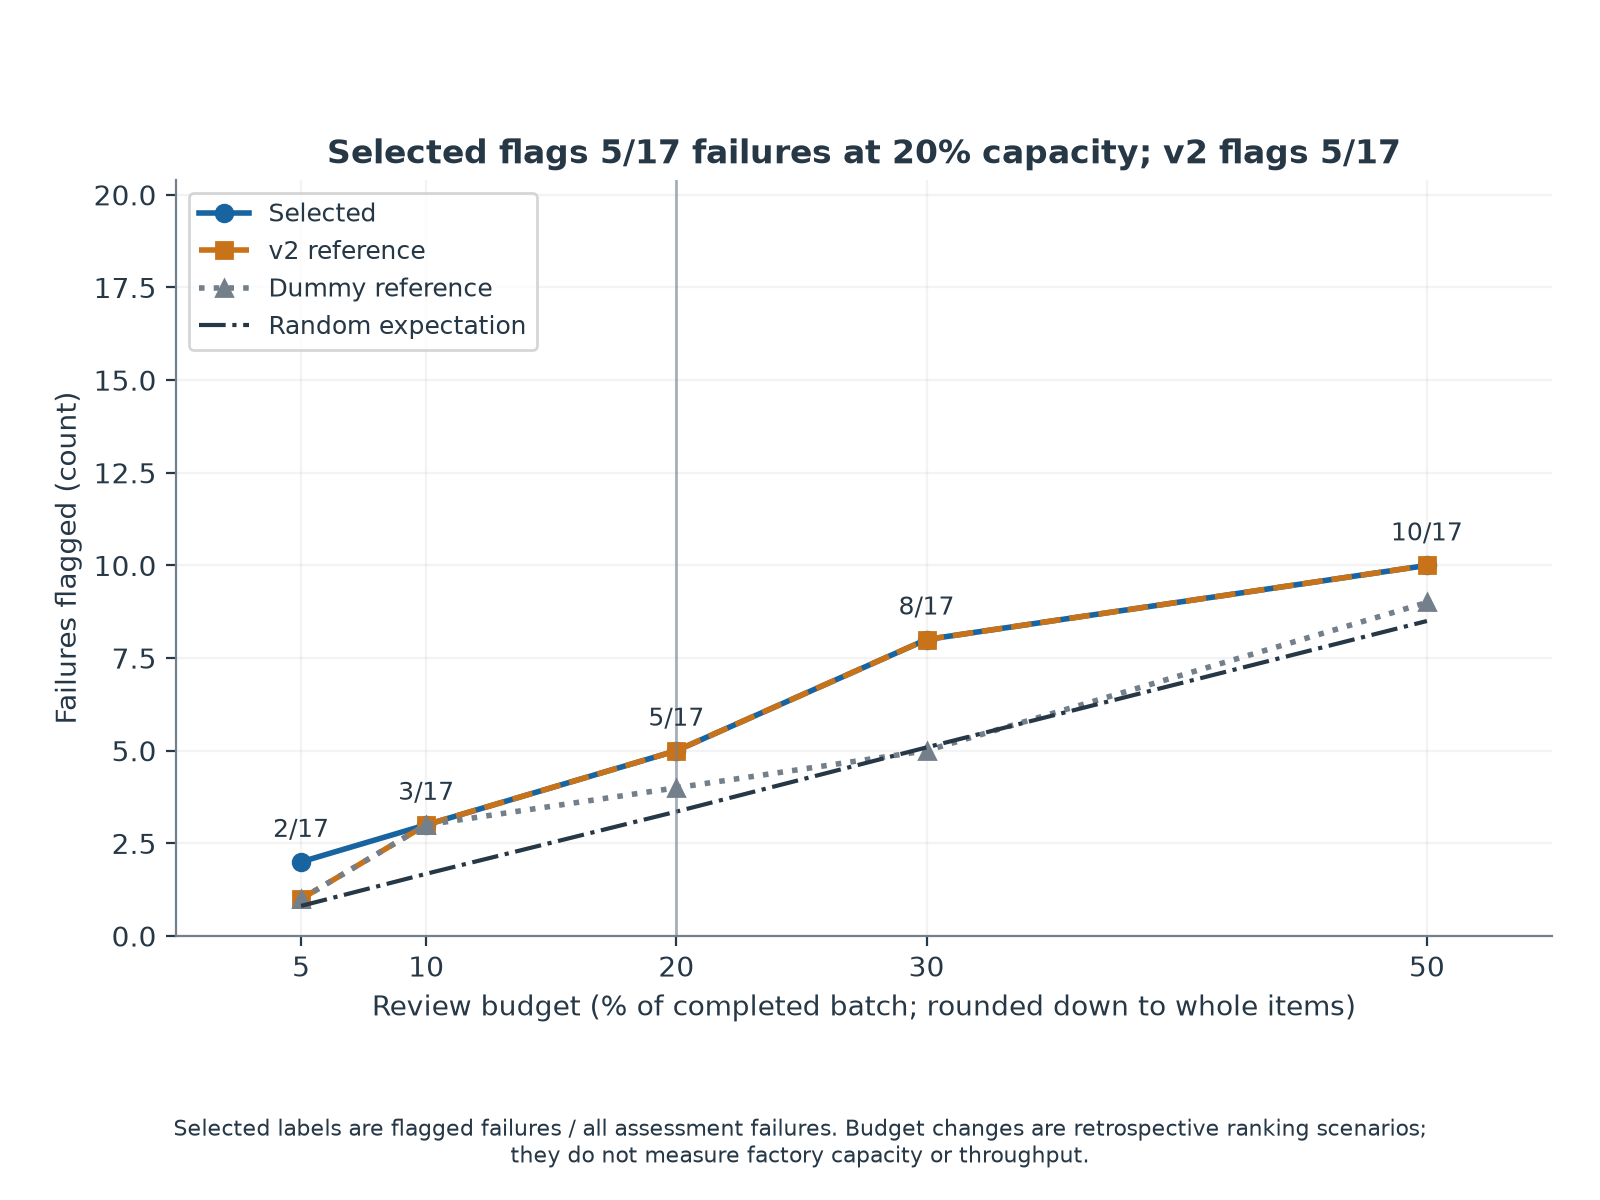

In [6]:
budgets = pd.read_csv(OUT / 'assessment_budgets.csv')
display(budgets.loc[budgets.strategy.eq('selected'), ['review_fraction','alarm_count','true_positives','false_positives','false_negatives','precision','recall']])
selected_rows = predictions.loc[predictions.strategy.eq('selected')]
fixed = evaluate_policy(selected_rows.label, threshold_mask(selected_rows.score, selection['threshold_policy']['threshold']))
assert fixed == metrics['assessment']['selected']['fixed_threshold']
display(Image(filename=str(OUT / 'figures/detection_vs_capacity.png'), width=900))


## 5. Translate inspection decisions into explicit scenarios

The scenario model uses one normalized cost unit per review, assumed escape/review cost ratios, and assumed intervention effectiveness. It includes no additional review, full review, theoretical random review, and model-based review. An apparent simulated benefit is conditional on these assumptions and does not measure actual factory savings, prevented defects, yield, or throughput.

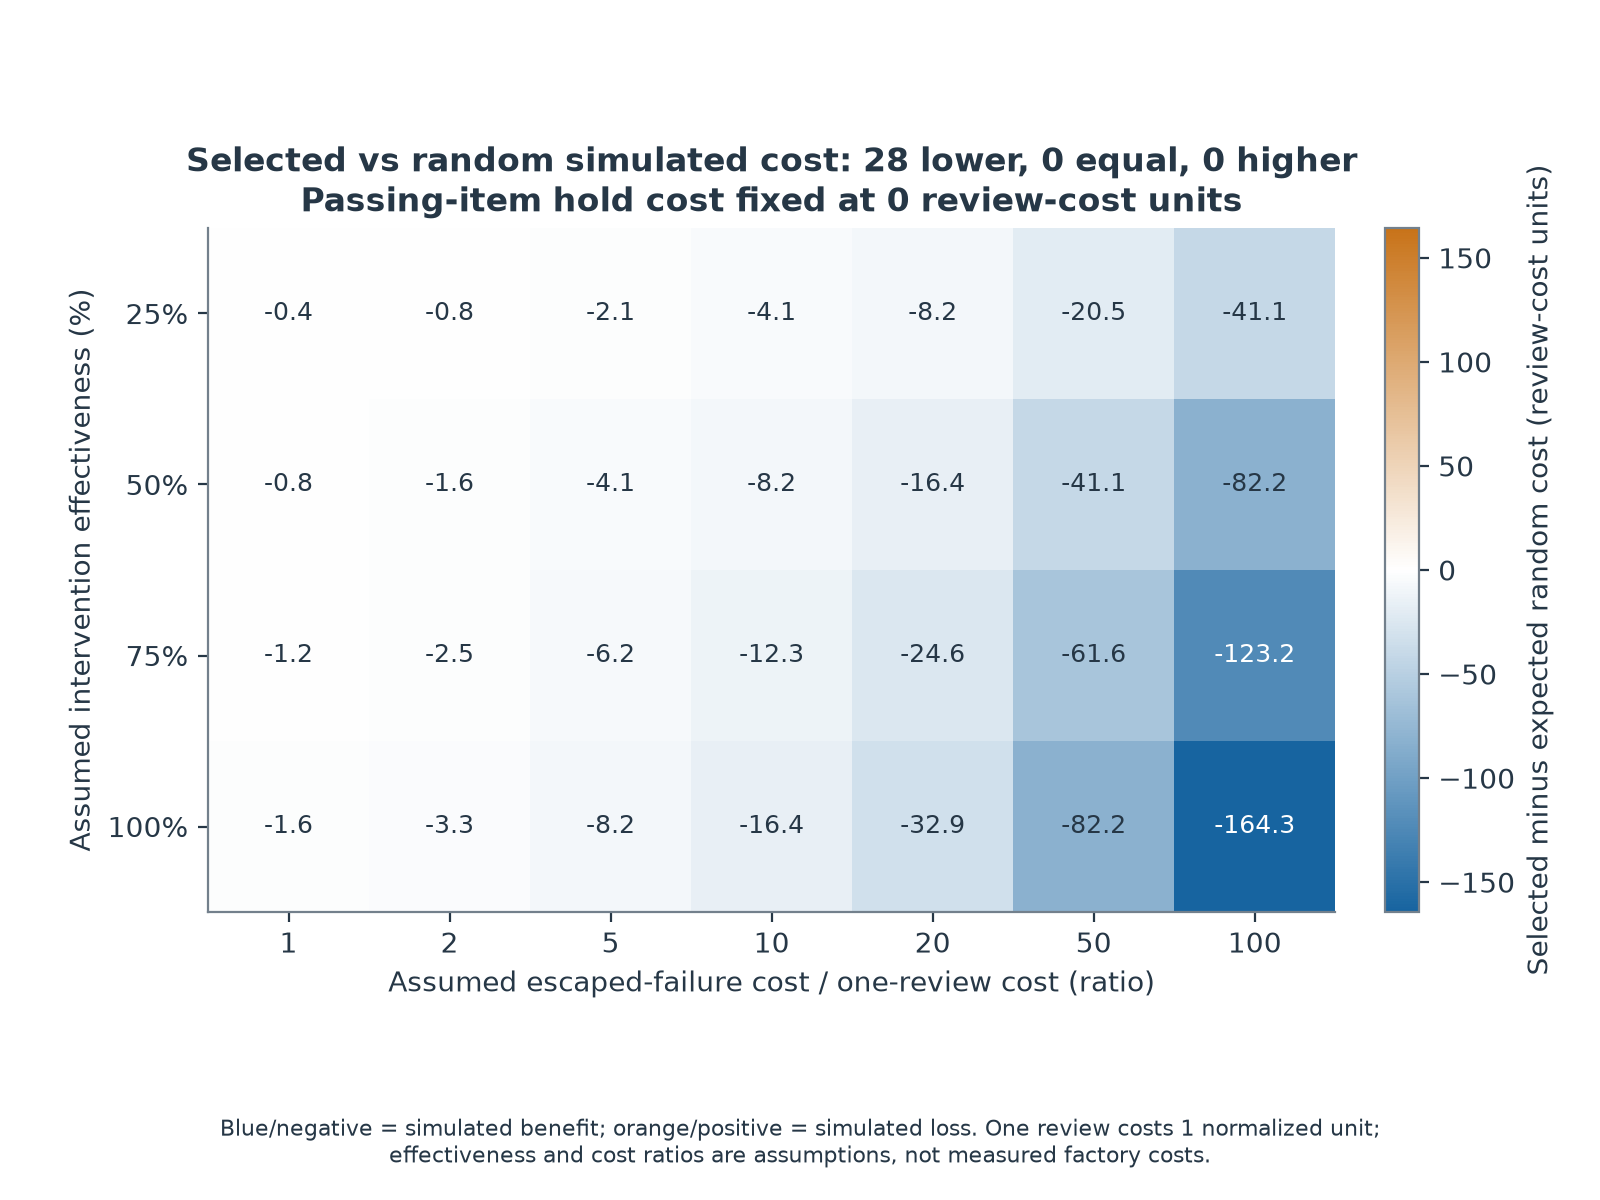

,strategy,simulated_total_cost_units,difference_vs_random
204,no_additional_review,340.000000,-28.433121
205,review_everything,484.000000,115.566879
206,random_same_capacity_expected,368.433121,0.000000
207,selected,352.000000,-16.433121
208,v2_reference,352.000000,-16.433121
209,dummy_reference,362.000000,-6.433121


In [7]:
scenarios = pd.read_csv(OUT / 'cost_scenarios.csv')
assert np.isfinite(scenarios.simulated_total_cost_units).all()
assert scenarios.loc[scenarios.strategy.eq('random_same_capacity_expected'),'difference_vs_random'].eq(0).all()
display(Image(filename=str(OUT / 'figures/cost_sensitivity.png'), width=1000))
display(scenarios.loc[scenarios.escape_cost_per_review_cost.eq(20) & scenarios.assumed_intervention_effectiveness.eq(.5) & scenarios.passing_hold_cost_per_review_cost.eq(0), ['strategy','simulated_total_cost_units','difference_vs_random']])


## Completed conclusion

The study produces a bounded 50-configuration search, a predeclared blend, forward selection, a frozen temporal assessment, reconstructable review decisions, six explained figures, and a usable batch scoring interface. These artifacts quantify what this dataset supports and where the detection/workload tradeoff remains weak.

The assessment contains only 17 failures. Previously explored data, changing temporal composition, uncalibrated scores, anonymous sensors, and unverified decision-time feature availability limit claims of future reliability. The complete evidence is in [the generated report](manufacturing_results/RESULTS.md), with the exact procedure in [the protocol](docs/15_smart_manufacturing_protocol.md). No error-free detector or actual production-capacity increase is claimed.